# BRD4-BD2 — Executed model validation notebook

**This notebook evaluates the previously trained ECFP4-RBF SVR model and verifies its saved predictions and scaffold-separated test partition.** Full hyperparameter search, repeated splits and y-randomization were previously executed and their outputs are read here rather than recomputed. The code for full retraining was archived separately in the earlier pipeline; this is a reproducible post-training validation notebook, not a claim of fresh retraining.

In [1]:
from pathlib import Path
import json, joblib, pandas as pd, numpy as np
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.metrics import r2_score, mean_squared_error,mean_absolute_error
root=Path("/mnt/data")
input_data=root/"BRD4_BD2_STRICT_MODELING_775.csv"
results=root/"BRD4_BD2_QSAR_RESULTS"
assert input_data.exists() and (results/"svr_model.joblib").exists()

## Saved-model validation on held-out structures

In [2]:
df=pd.read_csv(input_data)
preds=pd.read_csv(results/"heldout_predictions_with_AD.csv")
pack=joblib.load(results/"svr_model.joblib")
model=pack["pipeline"]
fpgen=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=2048)
X=np.stack([np.asarray(fpgen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)),dtype=np.float32) for s in preds.canonical_isomeric_smiles])
recomputed=model.predict(X)
assert np.allclose(recomputed,preds.predicted_pIC50,atol=1e-8)
print("Verified predictions:",len(preds))
print("R²:",round(r2_score(preds.observed_pIC50,recomputed),4))
print("RMSE:",round(np.sqrt(mean_squared_error(preds.observed_pIC50,recomputed)),4))
print("MAE:",round(mean_absolute_error(preds.observed_pIC50,recomputed),4))

Verified predictions: 187
R²: 0.6774
RMSE: 0.7329
MAE: 0.5763


## Scaffold overlap and previously computed repeated-split diagnostics

In [3]:
dev=df.loc[~df.canonical_isomeric_smiles.isin(preds.canonical_isomeric_smiles)].copy()
scf=lambda s: MurckoScaffold.MurckoScaffoldSmiles(smiles=s,includeChirality=False) or "NO_SCAFFOLD_"+s
train_scaff={scf(s) for s in dev.canonical_isomeric_smiles}
test_scaff={scf(s) for s in preds.canonical_isomeric_smiles}
assert len(train_scaff & test_scaff)==0
rep=pd.read_csv(results/"repeated_scaffold_20x_metrics.csv")
yrand=pd.read_csv(results/"y_randomization_30x.csv")
print("Development:",len(dev),"heldout:",len(preds),"shared Murcko scaffolds:",len(train_scaff&test_scaff))
print("Repeated scaffold splits:",len(rep),"mean R²:",round(rep.r2.mean(),3))
print("Y-randomization runs:",len(yrand))

Development: 588 heldout: 187 shared Murcko scaffolds: 0
Repeated scaffold splits: 20 mean R²: 0.647
Y-randomization runs: 30


## Saved held-out parity plot

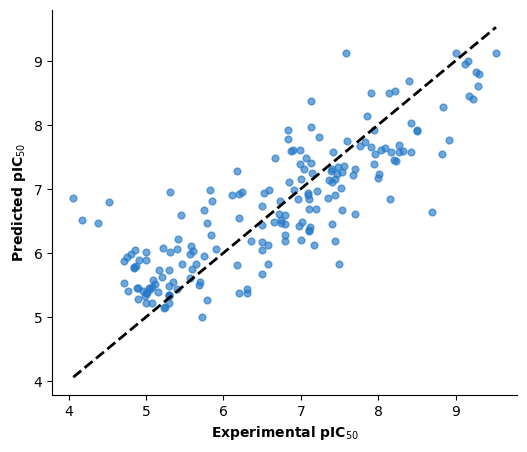

In [4]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(preds.observed_pIC50,preds.predicted_pIC50,s=24,alpha=.65,color="#2479c7")
lo=min(preds.observed_pIC50.min(),preds.predicted_pIC50.min());hi=max(preds.observed_pIC50.max(),preds.predicted_pIC50.max());ax.plot([lo,hi],[lo,hi],"--",color="black",lw=2)
ax.set_xlabel("Experimental pIC$_{50}$",fontweight="bold");ax.set_ylabel("Predicted pIC$_{50}$",fontweight="bold")
ax.spines["top"].set_visible(False);ax.spines["right"].set_visible(False)
plt.show()